In [1]:

import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(42)

centers = torch.tensor([
    [-2.0, -2.0],
    [2.0, -2.0],
    [0.0, 2.0]
])

X = torch.cat([
    torch.randn(100, 2) * 0.9 + center
    for center in centers
])

y = torch.arange(3).repeat_interleave(100)

indices = torch.randperm(len(X))

train_idx = indices[:210]
val_idx = indices[210:255]
test_idx = indices[255:]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

print(X_train.shape, X_val.shape, X_test.shape)


torch.Size([210, 2]) torch.Size([45, 2]) torch.Size([45, 2])


In [2]:

teacher = nn.Sequential(
    nn.Linear(2, 64),
    nn.ReLU(),
    nn.Linear(64, 64),
    nn.ReLU(),
    nn.Linear(64, 3)
)

student = nn.Sequential(
    nn.Linear(2, 8),
    nn.ReLU(),
    nn.Linear(8, 3)
)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

print("Teacher parameters:", count_parameters(teacher))
print("Student parameters:", count_parameters(student))


Teacher parameters: 4547
Student parameters: 51


Teacher test accuracy: 1.0


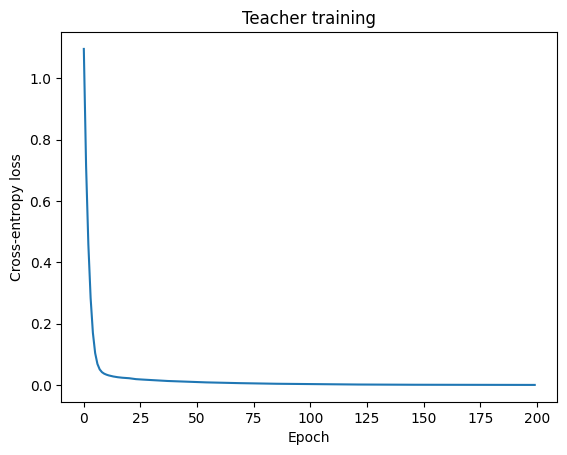

In [3]:

teacher_optimizer = torch.optim.Adam(teacher.parameters(), lr=0.01)

teacher_losses = []

for epoch in range(200):
    teacher.train()

    logits = teacher(X_train)
    loss = F.cross_entropy(logits, y_train)

    teacher_optimizer.zero_grad()
    loss.backward()
    teacher_optimizer.step()

    teacher_losses.append(loss.item())

teacher.eval()

with torch.no_grad():
    test_logits = teacher(X_test)
    teacher_accuracy = (
        (test_logits.argmax(dim=1) == y_test).float().mean()
    )

print("Teacher test accuracy:", teacher_accuracy.item())

plt.plot(teacher_losses)
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Teacher training")
plt.show()
